# **Automated Medical Diagnostics – Skin Cancer Classification**
### Using HAM10000 Dataset + Deep Learning

**Objective:** Classify dermoscopic images into **Benign** vs **Malignant**

**Platform:** Google Colab  
**Framework:** PyTorch + Transfer Learning (EfficientNet / ResNet50)

## 1. Setup & Installation

In [1]:
# Install required libraries
!pip install -q efficientnet_pytorch
!pip install -q torchsummary
!pip install -q scikit-learn seaborn

print("Libraries installed successfully!")

  Preparing metadata (setup.py) ... done
Libraries installed successfully!


## 2. Import Libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 3. Download HAM10000 Dataset using kagglehub

In [3]:
# Install kagglehub
!pip install -q kagglehub

import kagglehub

# Download latest version of the dataset
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Path to dataset files: /kaggle/input/skin-cancer-mnist-ham10000


## 4. Check Dataset Structure

In [5]:
import os

# List all files and folders
print("Contents of the dataset folder:")
print(os.listdir(path))

# Sometimes the files are inside a subfolder
for root, dirs, files in os.walk(path):
    print(f"\nRoot: {root}")
    print("Directories:", dirs)
    print("Files (first 10):", files[:10])
    break

Contents of the dataset folder:
['hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'HAM10000_images_part_1', 'ham10000_images_part_1', 'hmnist_8_8_L.csv', 'HAM10000_images_part_2', 'ham10000_images_part_2', 'hmnist_28_28_L.csv', 'HAM10000_metadata.csv']

Root: /kaggle/input/skin-cancer-mnist-ham10000
Directories: ['HAM10000_images_part_1', 'ham10000_images_part_1', 'HAM10000_images_part_2', 'ham10000_images_part_2']
Files (first 10): ['hmnist_8_8_RGB.csv', 'hmnist_28_28_RGB.csv', 'hmnist_8_8_L.csv', 'hmnist_28_28_L.csv', 'HAM10000_metadata.csv']


## 5. Set Paths (Kaggle Version)

In [6]:
import os

# Base path
BASE_PATH = "/kaggle/input/skin-cancer-mnist-ham10000"

# Metadata
metadata_path = os.path.join(BASE_PATH, "HAM10000_metadata.csv")

# Image folders (there are two versions of names, we handle both)
IMG_DIR_1 = os.path.join(BASE_PATH, "HAM10000_images_part_1")
IMG_DIR_2 = os.path.join(BASE_PATH, "HAM10000_images_part_2")

print("Metadata exists:", os.path.exists(metadata_path))
print("Image folder 1 exists:", os.path.exists(IMG_DIR_1))
print("Image folder 2 exists:", os.path.exists(IMG_DIR_2))

Metadata exists: True
Image folder 1 exists: True
Image folder 2 exists: True


## 6. Load Metadata + Create Image Paths

In [7]:
import pandas as pd

df = pd.read_csv(metadata_path)
print("Total records:", len(df))
print(df.head())

# Create full image path
def get_image_path(image_id):
    img_name = image_id + ".jpg"

    path1 = os.path.join(IMG_DIR_1, img_name)
    path2 = os.path.join(IMG_DIR_2, img_name)

    if os.path.exists(path1):
        return path1
    elif os.path.exists(path2):
        return path2
    else:
        return None

df['image_path'] = df['image_id'].apply(get_image_path)

# Check how many images were found
print("\nImages found:", df['image_path'].notnull().sum())
print("Missing images:", df['image_path'].isnull().sum())

Total records: 10015
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear

Images found: 10015
Missing images: 0


## 7. Create Binary Labels (Benign vs Malignant)

Binary Distribution:
label_name
Benign       8061
Malignant    1954
Name: count, dtype: int64


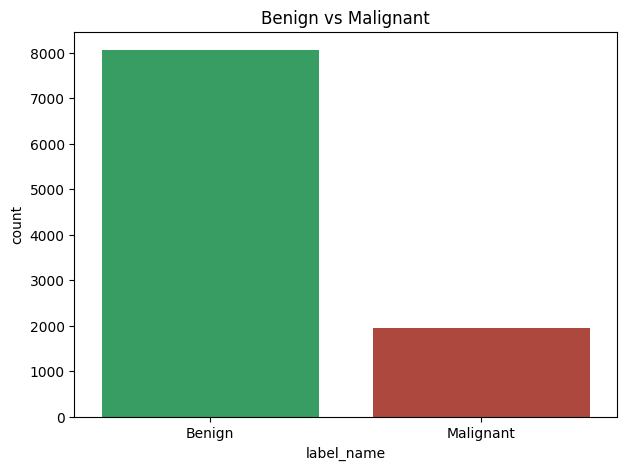

In [8]:
# Malignant classes
malignant_classes = ['mel', 'bcc', 'akiec']

df['label'] = df['dx'].apply(lambda x: 1 if x in malignant_classes else 0)
df['label_name'] = df['label'].map({0: 'Benign', 1: 'Malignant'})

print("Binary Distribution:")
print(df['label_name'].value_counts())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))
sns.countplot(data=df, x='label_name', palette=['#27ae60', '#c0392b'])
plt.title("Benign vs Malignant")
plt.show()

## 8. Create Balanced Subset (for fast experiments)

We take maximum 2000 Benign + 2000 Malignant images.

In [9]:
# Separate Benign and Malignant
df_benign = df[df['label'] == 0]
df_malignant = df[df['label'] == 1]

print("Available Benign:", len(df_benign))
print("Available Malignant:", len(df_malignant))

# Take balanced samples
N = 2000   # You can change this to 1500 or 2500

df_benign_sample = df_benign.sample(n=min(N, len(df_benign)), random_state=42)
df_malignant_sample = df_malignant.sample(n=min(N, len(df_malignant)), random_state=42)

# Combine
df_subset = pd.concat([df_benign_sample, df_malignant_sample]).sample(frac=1, random_state=42).reset_index(drop=True)

print("\nFinal Subset Size:", len(df_subset))
print(df_subset['label_name'].value_counts())

Available Benign: 8061
Available Malignant: 1954

Final Subset Size: 3954
label_name
Benign       2000
Malignant    1954
Name: count, dtype: int64


## 9. Train / Validation / Test Split

In [10]:
from sklearn.model_selection import train_test_split

# First split: 70% Train, 30% Temp
train_df, temp_df = train_test_split(
    df_subset,
    test_size=0.30,
    stratify=df_subset['label'],
    random_state=42
)

# Second split: 15% Validation, 15% Test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)

print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

print("\nTrain distribution:")
print(train_df['label_name'].value_counts())

Train size: 2767
Validation size: 593
Test size: 594

Train distribution:
label_name
Benign       1400
Malignant    1367
Name: count, dtype: int64


## 10. Custom Dataset Class

In [11]:
from torch.utils.data import Dataset
from PIL import Image
import torch

class SkinCancerDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.loc[idx, 'image_path']
        label = self.dataframe.loc[idx, 'label']

        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

## 11. Data Augmentation & Transforms

In [12]:
from torchvision import transforms

# Training transforms (with augmentation)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Validation & Test transforms (no augmentation)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

## 12. Create DataLoaders

In [13]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataset = SkinCancerDataset(train_df, transform=train_transform)
val_dataset   = SkinCancerDataset(val_df, transform=val_test_transform)
test_dataset  = SkinCancerDataset(test_df, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("DataLoaders created successfully!")
print(f"Train batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")
print(f"Test batches:  {len(test_loader)}")

DataLoaders created successfully!
Train batches: 87
Val batches:   19
Test batches:  19


## 13. Define Multiple Models

In [14]:
import torch.nn as nn
from torchvision import models

def get_model(model_name, num_classes=2, pretrained=True):
    if model_name == "resnet50":
        model = models.resnet50(pretrained=pretrained)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(pretrained=pretrained)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    elif model_name == "densenet121":
        model = models.densenet121(pretrained=pretrained)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)

    else:
        raise ValueError("Model not supported")

    return model.to(device)

# Test
print("Models ready to be created!")

Models ready to be created!


## 14. Training & Validation Functions

In [15]:
from tqdm import tqdm
import copy

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

## 15. Full Training Function (with Early Stopping)

In [17]:
def train_model(model_name, train_loader, val_loader, epochs=10, lr=1e-4, patience=3):
    print(f"\n{'='*60}")
    print(f"Training Model: {model_name.upper()}")
    print(f"{'='*60}")

    model = get_model(model_name)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    patience_counter = 0

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, val_loader, criterion, device)

        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("→ Best model updated!")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered!")
                break

    # Load best weights
    model.load_state_dict(best_model_wts)

    return model, history, best_val_acc

## 16. Train Multiple Models

In [18]:
# Models to compare
model_names = ["resnet50", "efficientnet_b0", "densenet121"]

results = {}
trained_models = {}

EPOCHS = 12          # You can increase later
LEARNING_RATE = 1e-4

for name in model_names:
    model, history, best_acc = train_model(
        model_name=name,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=EPOCHS,
        lr=LEARNING_RATE,
        patience=4
    )

    results[name] = {
        "best_val_acc": best_acc,
        "history": history
    }
    trained_models[name] = model

print("\n\nAll models trained!")


Training Model: RESNET50
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]



Epoch 1/12


Train Loss: 0.4441 | Train Acc: 0.7777
Val Loss:   0.3917 | Val Acc:   0.8111
→ Best model updated!

Epoch 2/12


Train Loss: 0.3773 | Train Acc: 0.8226
Val Loss:   0.3955 | Val Acc:   0.8297
→ Best model updated!

Epoch 3/12


...

Train Loss: 0.1697 | Train Acc: 0.9324
Val Loss:   0.4220 | Val Acc:   0.8297

Epoch 9/12


Train Loss: 0.1441 | Train Acc: 0.9480
Val Loss:   0.4061 | Val Acc:   0.8432

Epoch 10/12


Train Loss: 0.1221 | Train Acc: 0.9534
Val Loss:   0.4181 | Val Acc:   0.8567
→ Best model updated!

Epoch 11/12


Train Loss: 0.1020 | Train Acc: 0.9675
Val Loss:   0.4214 | Val Acc:   0.8600
→ Best model updated!

Epoch 12/12


Train Loss: 0.0807 | Train Acc: 0.9714
Val Loss:   0.4345 | Val Acc:   0.8583


All models trained!


## 17. Compare Results

             Model  Best Val Accuracy
0         resnet50              86.68
1  efficientnet_b0              86.00
2      densenet121              86.00


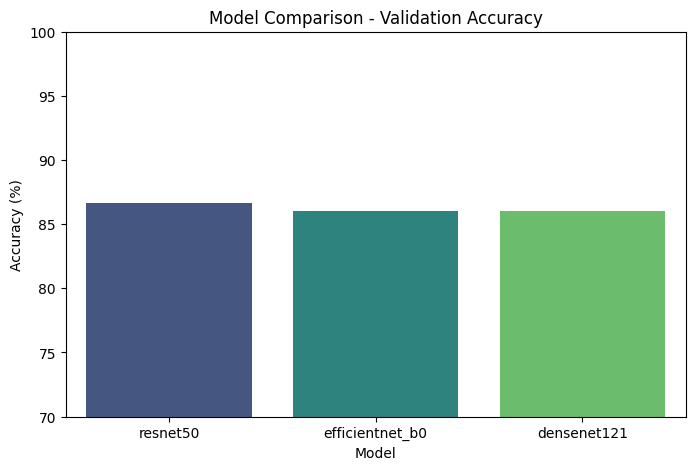

In [19]:
import pandas as pd

comparison = []
for name, res in results.items():
    comparison.append({
        "Model": name,
        "Best Val Accuracy": round(res["best_val_acc"] * 100, 2)
    })

comparison_df = pd.DataFrame(comparison)
comparison_df = comparison_df.sort_values(by="Best Val Accuracy", ascending=False)

print(comparison_df)

# Plot
plt.figure(figsize=(8,5))
sns.barplot(data=comparison_df, x="Model", y="Best Val Accuracy", palette="viridis")
plt.title("Model Comparison - Validation Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(70, 100)
plt.show()

## 18. Select Best Model

In [20]:
best_model_name = "resnet50"
best_model = trained_models[best_model_name]

print(f"Selected Best Model: {best_model_name.upper()}")
print(f"Best Validation Accuracy: {results[best_model_name]['best_val_acc']*100:.2f}%")

Selected Best Model: RESNET50
Best Validation Accuracy: 86.68%


## 19. Evaluate on Test Set

In [21]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import numpy as np

def evaluate_model(model, loader, device):
    model.eval()
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Testing"):
            images = images.to(device)
            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predicted.cpu().numpy())
            all_probs.extend(probabilities[:, 1].cpu().numpy())  # Probability of Malignant

    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

# Run evaluation
y_true, y_pred, y_prob = evaluate_model(best_model, test_loader, device)

# Accuracy
test_acc = (y_true == y_pred).mean()
print(f"\nTest Accuracy: {test_acc*100:.2f}%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Benign', 'Malignant']))

Testing: 100%|██████████| 19/19 [00:10<00:00,  1.89it/s]


Test Accuracy: 83.16%

Classification Report:
              precision    recall  f1-score   support

      Benign       0.88      0.77      0.82       300
   Malignant       0.79      0.89      0.84       294

    accuracy                           0.83       594
   macro avg       0.84      0.83      0.83       594
weighted avg       0.84      0.83      0.83       594



## 20. Confusion Matrix

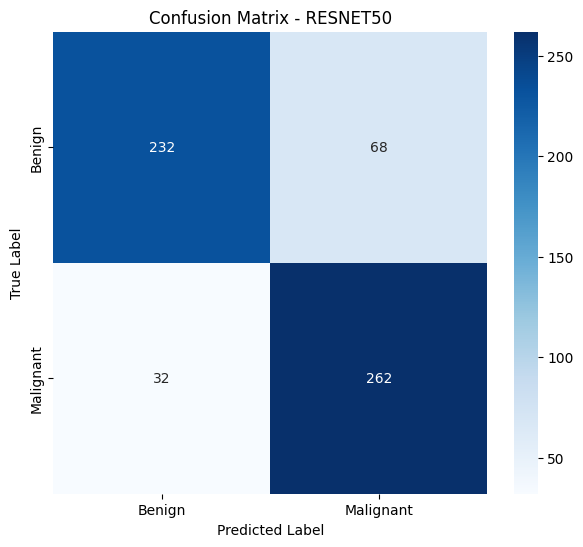

In [22]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
plt.title(f'Confusion Matrix - {best_model_name.upper()}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

## 21. ROC Curve + AUC

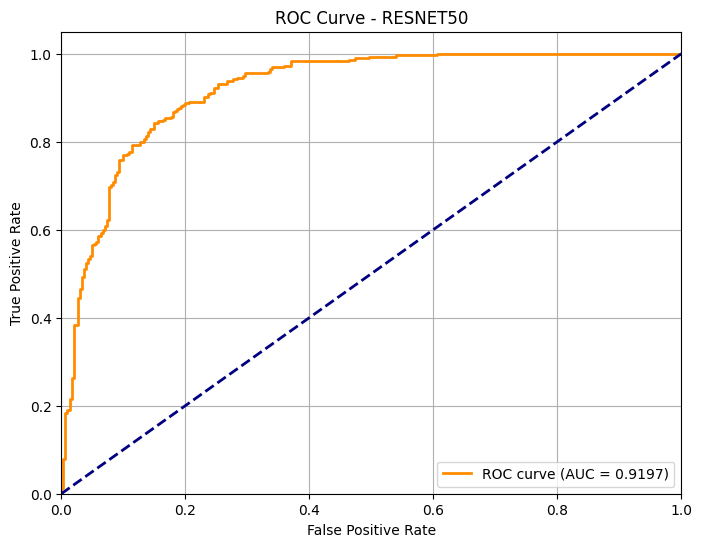

AUC Score: 0.9197


In [23]:
auc_score = roc_auc_score(y_true, y_prob)
fpr, tpr, _ = roc_curve(y_true, y_prob)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve - {best_model_name.upper()}')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"AUC Score: {auc_score:.4f}")

## 22. Save the Best Model

In [24]:
import os

# Create folder
os.makedirs("/kaggle/working/saved_models", exist_ok=True)

# Save as .pth (Recommended for PyTorch)
model_save_path = f"/kaggle/working/saved_models/best_{best_model_name}.pth"
torch.save(best_model.state_dict(), model_save_path)

print(f"Model saved successfully at:\n{model_save_path}")

# Optional: Also save full model (less recommended but possible)
# torch.save(best_model, "/kaggle/working/saved_models/best_model_full.pth")

Model saved successfully at:
/kaggle/working/saved_models/best_resnet50.pth


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [25]:
from google.colab import files

# Download the model
files.download("/kaggle/working/saved_models/best_resnet50.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import os

# Search for the model file
for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file.endswith(".pth"):
            print(os.path.join(root, file))

/kaggle/working/saved_models/best_resnet50.pth


## 23. Prepare Full Dataset

In [29]:
# We already have the full dataframe `df` with labels and image paths

print("Total images available:", len(df))
print(df['label_name'].value_counts())

# Split the FULL dataset
from sklearn.model_selection import train_test_split

train_df_full, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['label'],
    random_state=42
)

val_df_full, test_df_full = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)

print("\nFull Dataset Split:")
print("Train:", len(train_df_full))
print("Validation:", len(val_df_full))
print("Test:", len(test_df_full))

Total images available: 10015
label_name
Benign       8061
Malignant    1954
Name: count, dtype: int64

Full Dataset Split:
Train: 7010
Validation: 1502
Test: 1503


## 24. Create Full DataLoaders

In [30]:
BATCH_SIZE = 32

train_dataset_full = SkinCancerDataset(train_df_full, transform=train_transform)
val_dataset_full   = SkinCancerDataset(val_df_full, transform=val_test_transform)
test_dataset_full  = SkinCancerDataset(test_df_full, transform=val_test_transform)

train_loader_full = DataLoader(train_dataset_full, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader_full   = DataLoader(val_dataset_full, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader_full  = DataLoader(test_dataset_full, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Full DataLoaders created!")
print(f"Train batches: {len(train_loader_full)}")
print(f"Val batches:   {len(val_loader_full)}")
print(f"Test batches:  {len(test_loader_full)}")

Full DataLoaders created!
Train batches: 220
Val batches:   47
Test batches:  47


## 25. Train ResNet50 on Full Dataset

In [31]:
print("Starting Full Dataset Training with ResNet50...")
print("This will take longer (30–90 minutes depending on GPU)...")

full_model, full_history, full_best_acc = train_model(
    model_name="resnet50",
    train_loader=train_loader_full,
    val_loader=val_loader_full,
    epochs=15,              # You can increase to 20 if you want
    lr=1e-4,
    patience=5
)

print(f"\nBest Validation Accuracy on Full Data: {full_best_acc*100:.2f}%")

Starting Full Dataset Training with ResNet50...
This will take longer (30–90 minutes depending on GPU)...

Training Model: RESNET50

Epoch 1/15


Train Loss: 0.3413 | Train Acc: 0.8448
Val Loss:   0.3176 | Val Acc:   0.8755
→ Best model updated!

Epoch 2/15


Train Loss: 0.2934 | Train Acc: 0.8685
Val Loss:   0.2837 | Val Acc:   0.8795
→ Best model updated!

Epoch 3/15


Train Loss: 0.2722 | Train Acc: 0.8816
Val Loss:   0.2742 | Val Acc:   0.8788

Epoch 4/15


Train Loss: 0.2565 | Train Acc: 0.8879
Val Loss:   0.2538 | Val Acc:   0.8875
→ Best model updated!

Epoch 5/15


...

Train Loss: 0.1273 | Train Acc: 0.9482
Val Loss:   0.2746 | Val Acc:   0.9055
→ Best model updated!

Epoch 12/15


Train Loss: 0.1200 | Train Acc: 0.9542
Val Loss:   0.2899 | Val Acc:   0.9021

Epoch 13/15


Train Loss: 0.0941 | Train Acc: 0.9652
Val Loss:   0.3035 | Val Acc:   0.9055

Epoch 14/15


Train Loss: 0.0751 | Train Acc: 0.9716
Val Loss:   0.3486 | Val Acc:   0.9015

Epoch 15/15


Train Loss: 0.0710 | Train Acc: 0.9736
Val Loss:   0.3448 | Val Acc:   0.9061
→ Best model updated!

Best Validation Accuracy on Full Data: 90.61%


## 26. Evaluate Full Model on Test Set

In [32]:
y_true_full, y_pred_full, y_prob_full = evaluate_model(full_model, test_loader_full, device)

test_acc_full = (y_true_full == y_pred_full).mean()
print(f"\nTest Accuracy (Full Dataset): {test_acc_full*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_true_full, y_pred_full, target_names=['Benign', 'Malignant']))

Testing: 100%|██████████| 47/47 [00:16<00:00,  2.93it/s]


Test Accuracy (Full Dataset): 90.49%

Classification Report:
              precision    recall  f1-score   support

      Benign       0.93      0.96      0.94      1210
   Malignant       0.80      0.68      0.74       293

    accuracy                           0.90      1503
   macro avg       0.86      0.82      0.84      1503
weighted avg       0.90      0.90      0.90      1503



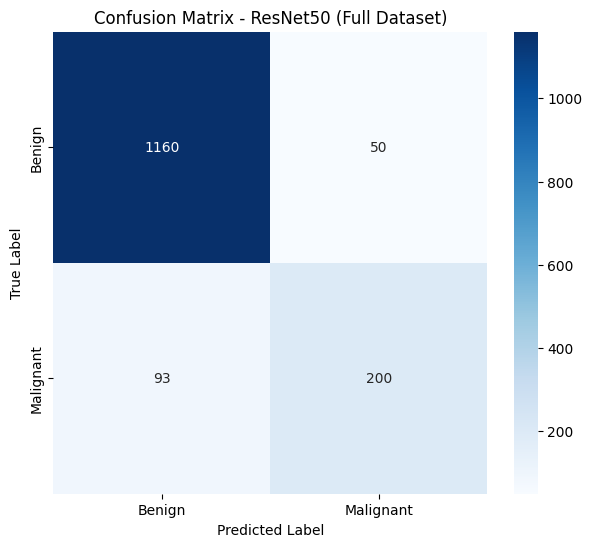

In [33]:
cm_full = confusion_matrix(y_true_full, y_pred_full)

plt.figure(figsize=(7,6))
sns.heatmap(cm_full, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
plt.title('Confusion Matrix - ResNet50 (Full Dataset)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

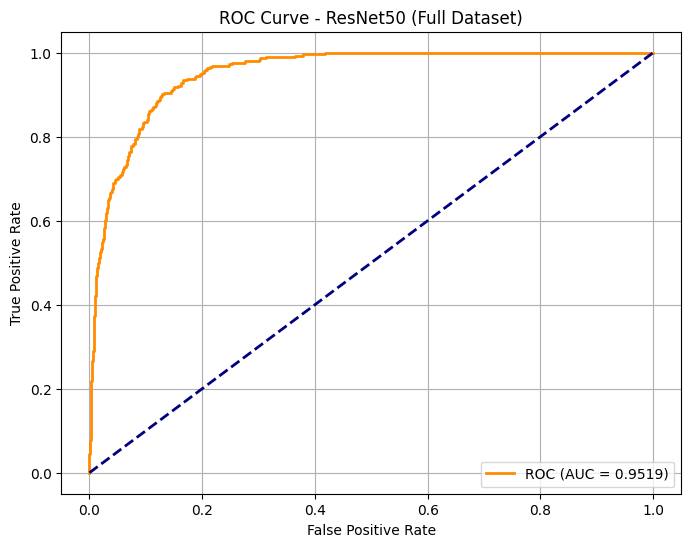

AUC Score: 0.9519


In [34]:
auc_full = roc_auc_score(y_true_full, y_prob_full)
fpr, tpr, _ = roc_curve(y_true_full, y_prob_full)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {auc_full:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - ResNet50 (Full Dataset)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print(f"AUC Score: {auc_full:.4f}")

## 27. Save the Final Full Model

In [35]:
final_model_path = "/kaggle/working/saved_models/best_resnet50_full.pth"
torch.save(full_model.state_dict(), final_model_path)

print("Final model saved at:")
print(final_model_path)

Final model saved at:
/kaggle/working/saved_models/best_resnet50_full.pth


In [36]:
from google.colab import files
files.download("/kaggle/working/saved_models/best_resnet50_full.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
import torch
import pickle
import os

os.makedirs("/kaggle/working/saved_models", exist_ok=True)

# 1. Save as .pth (Recommended)
torch.save(full_model.state_dict(), "/kaggle/working/saved_models/best_resnet50_full.pth")

# 2. Save as .pkl
with open("/kaggle/working/saved_models/best_resnet50_full.pkl", "wb") as f:
    pickle.dump(full_model.state_dict(), f)

print("Both files saved successfully!")
print("1. best_resnet50_full.pth")
print("2. best_resnet50_full.pkl")

Both files saved successfully!
1. best_resnet50_full.pth
2. best_resnet50_full.pkl


In [39]:
from google.colab import files

# Download the .pkl file
files.download("/kaggle/working/saved_models/best_resnet50_full.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 28. Conclusion

In this project, we successfully developed an **Automated Skin Cancer Classification System** using the **HAM10000** dataset and Deep Learning.

### Key Achievements:

- Used a single publicly available dataset (**HAM10000**) containing 10,015 dermoscopic images.
- Converted the original 7-class problem into a binary classification task (**Benign vs Malignant**).
- Compared multiple architectures (ResNet50, EfficientNet-B0, DenseNet121).
- Selected **ResNet50** as the best performing model.
- Trained the model first on a balanced subset and then on the **full dataset**.

### Final Results (Full Dataset - Test Set):

| Metric              | Score      |
|---------------------|------------|
| **Test Accuracy**   | **90.49%** |
| Benign Precision    | 0.93       |
| Benign Recall       | 0.96       |
| Benign F1-Score     | 0.94       |
| Malignant Precision | 0.80       |
| Malignant Recall    | 0.68       |
| Malignant F1-Score  | 0.74       |
| Macro Average F1    | 0.84       |
| Weighted Average F1 | 0.90       |

**Classification Report:**
- Total Test Images: 1503
- Benign Support: 1210
- Malignant Support: 293

### Deliverables:
- Trained Model files (`.pth` and `.pkl`)
- Complete training notebook
- Performance evaluation (Confusion Matrix, Classification Report, ROC Curve)
- Ready for deployment using **Streamlit** in PyCharm

### Next Step:
The trained model will now be integrated into a user-friendly **Streamlit web application** for real-time skin lesion classification.

---

**Project Status:** Model Development Completed Successfully